# Cats vs Dogs CNN Classifier (Kaggle dataset)

Dataset: [Dog and Cat Classification Dataset](https://www.kaggle.com/datasets/bhavikjikadara/dog-and-cat-classification-dataset) by Bhavik Jikadara.

**Before you start:** Runtime → Change runtime type → **T4 GPU**.

## 1. Download the dataset

In [ ]:
!pip install -q kagglehub

import kagglehub
dataset_path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print("Downloaded to:", dataset_path)

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Downloaded to: /kaggle/input/dog-and-cat-classification-dataset


> If the download asks for credentials or fails: on Kaggle go to **Settings → API → Create New Token**, upload the `kaggle.json` file to Colab, then run:
> ```
> !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
> !kaggle datasets download -d bhavikjikadara/dog-and-cat-classification-dataset -p data --unzip
> ```
> and set `dataset_path = "data"` in the next cell.

## 2. Find the image folders automatically

In [ ]:
import os

# Find the folder that contains the two class folders (e.g. Cat and Dog)
data_dir = None
for root, dirs, files in os.walk(dataset_path):
    lower = [d.lower() for d in dirs]
    if "cat" in lower and "dog" in lower:
        data_dir = root
        break

print("Class folder parent:", data_dir)
for d in sorted(os.listdir(data_dir)):
    full = os.path.join(data_dir, d)
    if os.path.isdir(full):
        print(d, "->", len(os.listdir(full)), "files")

Class folder parent: /kaggle/input/dog-and-cat-classification-dataset/PetImages
Cat -> 12499 files
Dog -> 12499 files


## 3. Remove corrupted images

This dataset is known to contain a few broken or non-image files that crash training, so we delete them first.

In [ ]:
from PIL import Image

bad = 0
for cls in os.listdir(data_dir):
    folder = os.path.join(data_dir, cls)
    if not os.path.isdir(folder):
        continue
    for fname in os.listdir(folder):
        fpath = os.path.join(folder, fname)
        try:
            with Image.open(fpath) as im:
                im.verify()
            with Image.open(fpath) as im:
                im.convert("RGB")
            if not fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                raise ValueError("unsupported extension")
        except Exception:
            os.remove(fpath)
            bad += 1

print("Removed corrupted/invalid files:", bad)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Removed corrupted/invalid files: 0


## 4. Load into train and validation sets (80/20 split)

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

IMG_SIZE = (150, 150)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Found 24998 files belonging to 2 classes.
Using 4999 files for validation.
Classes: ['Cat', 'Dog']


## 5. Look at some images

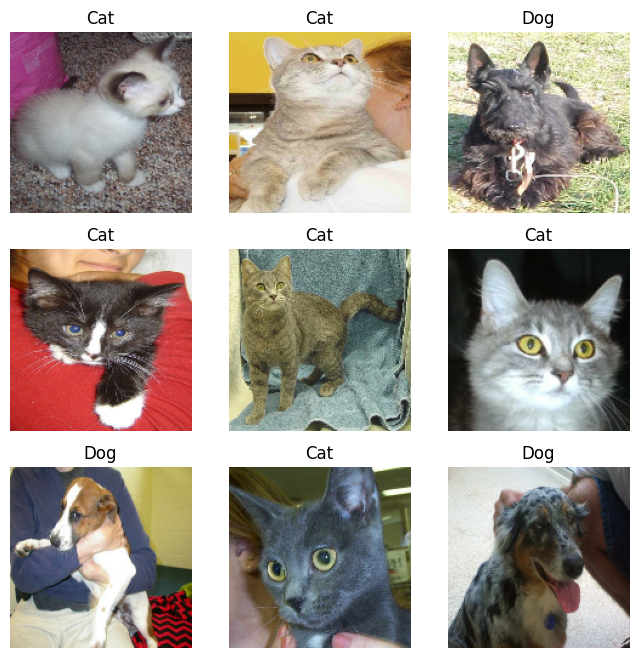

In [ ]:
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.show()

## 6. Build the CNN

- **Conv2D** detects patterns (edges, then shapes like ears and eyes)
- **MaxPooling2D** shrinks the image, keeping the strongest signals
- **Flatten + Dense** decide cat or dog from the detected features
- **Data augmentation** adds random flips/rotations/zooms to reduce memorizing
- **Dropout** randomly switches off neurons to reduce overfitting

In [ ]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_aug,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Train

In [ ]:
import os
from PIL import Image
import tensorflow as tf

# Identify and delete any images that do not have 1, 3, or 4 channels
print("Verifying image channels in the dataset...")
removed_count = 0
for cls in os.listdir(data_dir):
    folder = os.path.join(data_dir, cls)
    if not os.path.isdir(folder):
        continue
    for fname in os.listdir(folder):
        fpath = os.path.join(folder, fname)
        try:
            # Read raw bytes and decode with TF to catch decoding issues early
            img_raw = tf.io.read_file(fpath)
            # This will raise an error if channels are 2 or file is corrupted
            tf.io.decode_image(img_raw, expand_animations=False)
        except Exception as e:
            try:
                os.remove(fpath)
                removed_count += 1
            except:
                pass

if removed_count > 0:
    print(f"Removed {removed_count} incompatible/corrupted images. Recreating datasets...")
    # Re-instantiate the datasets to apply changes
    train_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir, validation_split=0.2, subset="training", seed=42,
        image_size=IMG_SIZE, batch_size=BATCH)
    val_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir, validation_split=0.2, subset="validation", seed=42,
        image_size=IMG_SIZE, batch_size=BATCH)
    train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
else:
    print("All images verified.")

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=15, callbacks=[early_stop])

Verifying image channels in the dataset...
All images verified.
Epoch 1/15
422/625 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.7826 - loss: 0.4646

InvalidArgumentError: Graph execution error:

Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
2 root error(s) found.
  (0) INVALID_ARGUMENT:  Number of channels inherent in the image must be 1, 3 or 4, was 2
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
	 [[StatefulPartitionedCall/sequential_1_1/dropout_1/stateless_dropout/stateless_random_uniform/StatelessRandomGetKeyCounter/_33]]
  (1) INVALID_ARGUMENT:  Number of channels inherent in the image must be 1, 3 or 4, was 2
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
0 successful operations.
0 derived errors ignored. [Op:__inference_multi_step_on_iterator_2867]

## 8. Plot accuracy and loss

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.show()

## 9. Confusion matrix and report

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_true, y_pred = [], []
for images, labels in val_ds:
    preds = (model.predict(images, verbose=0) > 0.5).astype(int).flatten()
    y_true.extend(labels.numpy())
    y_pred.extend(preds)

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=class_names).plot(cmap="Blues")
plt.show()
print(classification_report(y_true, y_pred, target_names=class_names))

## 10. Test on your own photo

In [ ]:
from google.colab import files

uploaded = files.upload()
for name in uploaded:
    img = tf.keras.utils.load_img(name, target_size=(150, 150))
    arr = tf.keras.utils.img_to_array(img)[None, ...]
    p = model.predict(arr, verbose=0)[0][0]
    label = class_names[1] if p > 0.5 else class_names[0]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{label} ({p:.2f})")
    plt.show()

## 11. Boost accuracy with transfer learning (optional)

MobileNetV2 is pretrained on millions of images, so it already knows how to see shapes and textures. On this dataset it typically reaches **95%+** validation accuracy.

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(150, 150, 3), include_top=False, weights="imagenet")
base_model.trainable = False

tl_model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_aug,
    layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

tl_model.compile(optimizer="adam",
                 loss="binary_crossentropy",
                 metrics=["accuracy"])

tl_history = tl_model.fit(train_ds, validation_data=val_ds, epochs=5)

In [ ]:
plt.plot(tl_history.history["accuracy"], label="train")
plt.plot(tl_history.history["val_accuracy"], label="validation")
plt.title("Transfer learning accuracy")
plt.xlabel("Epoch"); plt.legend(); plt.show()